In [1]:
import numpy as np
import pandas as pd
from scipy.io import loadmat
from pathlib import Path
import matplotlib.pyplot as plt

Processing

In [ ]:
parent_dir = Path(r'Z:\Nino\Projects\SIZ_WaddellLab\SIZ')
                  
f_rec = 1.17 #  imaging frame rate in Hz

master_data = []

# frame window range
window_range_before = 3
window_range_after = 9

# Loop through all folders
for brain_folder in parent_dir.glob('brain*'):
    # Loop through all subfolders within each brain folder
    for trial_folder in brain_folder.glob('trial*'):
        print(f'INFO: now processing {trial_folder}')
        
        p_csvs = [*trial_folder.glob('**/ROI.csv')]

        p_xlsx = [*trial_folder.glob('**/Stimulation_frames.xlsx')]

        # Read text file in the trial folder
        text_file_path = next(trial_folder.glob('trial*.txt'), None)
        if not text_file_path:
            print(f"WARNING: No .txt file found in {trial_folder}")
            continue

        # Extract stimulation frames
        if p_xlsx:
            df_stim = pd.read_excel(p_xlsx[0], header=None)
            stim_frames = df_stim.iloc[:, 0].dropna().astype(int).tolist()
        else:
            print(f"WARNING: No stimulation frames found in {trial_folder}")
            continue

        # Read stimulation pattern
        with open(text_file_path, 'r') as file:
            pattern = [int(value) for line in file for value in line.split()]


        if len(pattern) != len(stim_frames):
            print(
                f"WARNING: number of stim values ({len(pattern)}) "
                f"does not match stim frames ({len(stim_frames)})"
            )
            continue

        # Process CSV and corresponding .mat files
        for p_csv in p_csvs:
            print(f'INFO: now parsing {p_csv}')
            
            df_rec = pd.read_csv(p_csv)
            df_rec.rename(columns={df_rec.columns[0]: 'original frame'}, inplace=True)
            df_rec.index = range(1, len(df_rec) + 1)

            # Find ROI columns
            roi_cols = [c for c in df_rec.columns if c.lower().startswith("mean")]

            # Last ROI is background
            background = df_rec[roi_cols[-1]]

            # Signal ROIs
            signal_rois = roi_cols[:-1]

            # Calculate background substracted fluorescence F for every ROI
            for roi in signal_rois:

                f_col = roi.replace("Mean", "ROI") + "_F"

                df_rec[f_col] = df_rec[roi] - background
                df_rec[f_col + "_smth"] = (
                df_rec[f_col]
                .rolling(window=2, center=True) # smooth with a moving average of 2 frames
                .mean()
                )

            df_rec['stimulation_cycle'] = np.nan
            df_rec['condition'] = pd.Series(index=df_rec.index, dtype="Int64")
            df_rec['new_frames'] = np.nan

            # Process each stimulation frame
            for i, stim_frame in enumerate(stim_frames):
                if stim_frame is None:
                    continue
                
                # Define the window for the current stimulation cycle
                start_frame = stim_frame - window_range_before
                end_frame = stim_frame + window_range_after

                in_window = (df_rec['original frame'] >= start_frame) & (df_rec['original frame'] <= end_frame)
                df_rec.loc[in_window, 'stimulation_cycle'] = i + 1
                df_rec.loc[in_window, 'condition'] = pattern[i]

                # Align time to stimulation
                df_rec.loc[in_window, 'new_frames'] = (
                    df_rec.loc[in_window, 'original frame'] - stim_frame
                )

            df_rec = df_rec[df_rec['stimulation_cycle'].notna()]
          
            # Calculate F0 for each stimulation cycle
            f0_values = {}

            for cycle in df_rec['stimulation_cycle'].unique():
                cycle_data = df_rec[df_rec['stimulation_cycle'] == cycle]
                stim_frame = stim_frames[int(cycle) - 1]
                
                # Define the F0 window
                f0_window_start = stim_frame - 3
                f0_window_end = stim_frame - 0

                # Adjust window boundaries
                session_window_data = cycle_data[(cycle_data['original frame'] >= f0_window_start) & 
                                                 (cycle_data['original frame'] < f0_window_end)]

                for roi in signal_rois:

                    f_col = roi.replace("Mean", "ROI") + "_F"

                    if roi not in f0_values:
                        f0_values[roi] = {}

                    f0_values[roi][cycle] = session_window_data[f_col].mean()

            for roi in signal_rois:

                f_col = roi.replace("Mean", "ROI") + "_F"
                smth_col = f_col + "_smth"

                f0_col = roi.replace("Mean", "ROI") + "_F0"
                dff_col = roi.replace("Mean", "ROI") + "_dF_F0"
                #z_col = roi.replace("Mean", "ROI") + "_z"

                df_rec[f0_col] = df_rec["stimulation_cycle"].map(f0_values[roi])

                # Calculate ΔF/F0 
                df_rec[dff_col] = (
                df_rec[smth_col] - df_rec[f0_col]
                ) / df_rec[f0_col]

                # Calculate z-scored ΔF/F0 
                #df_rec[z_col] = (
                #df_rec[dff_col] - df_rec[dff_col].mean()
                #) / df_rec[dff_col].std()

            df_rec['brain'] = brain_folder.name
            df_rec['trial'] = trial_folder.name

            master_data.append(df_rec)

# Create a single DataFrame
master_df = pd.concat(master_data, ignore_index=True)

master_df.to_csv(parent_dir / 'master_data_with_F0_dF_F0.csv', index=False)

print(f'Master DataFrame created with {len(master_df)} rows and saved to "master_data_stimulation_cycles.csv".')

INFO: now processing Z:\Nino\Projects\SIZ_WaddellLab\SIZ\brain12\trial2
INFO: now parsing Z:\Nino\Projects\SIZ_WaddellLab\SIZ\brain12\trial2\ROI.csv
INFO: now processing Z:\Nino\Projects\SIZ_WaddellLab\SIZ\brain12\trial1
INFO: now parsing Z:\Nino\Projects\SIZ_WaddellLab\SIZ\brain12\trial1\ROI.csv
INFO: now processing Z:\Nino\Projects\SIZ_WaddellLab\SIZ\brain20\trial4
INFO: now parsing Z:\Nino\Projects\SIZ_WaddellLab\SIZ\brain20\trial4\ROI.csv
INFO: now processing Z:\Nino\Projects\SIZ_WaddellLab\SIZ\brain15\trial2
INFO: now parsing Z:\Nino\Projects\SIZ_WaddellLab\SIZ\brain15\trial2\ROI.csv
INFO: now processing Z:\Nino\Projects\SIZ_WaddellLab\SIZ\brain15\trial1
INFO: now parsing Z:\Nino\Projects\SIZ_WaddellLab\SIZ\brain15\trial1\ROI.csv
INFO: now processing Z:\Nino\Projects\SIZ_WaddellLab\SIZ\brain14\trial2
INFO: now parsing Z:\Nino\Projects\SIZ_WaddellLab\SIZ\brain14\trial2\ROI.csv
INFO: now processing Z:\Nino\Projects\SIZ_WaddellLab\SIZ\brain14\trial1
INFO: now parsing Z:\Nino\Projects

Plotting

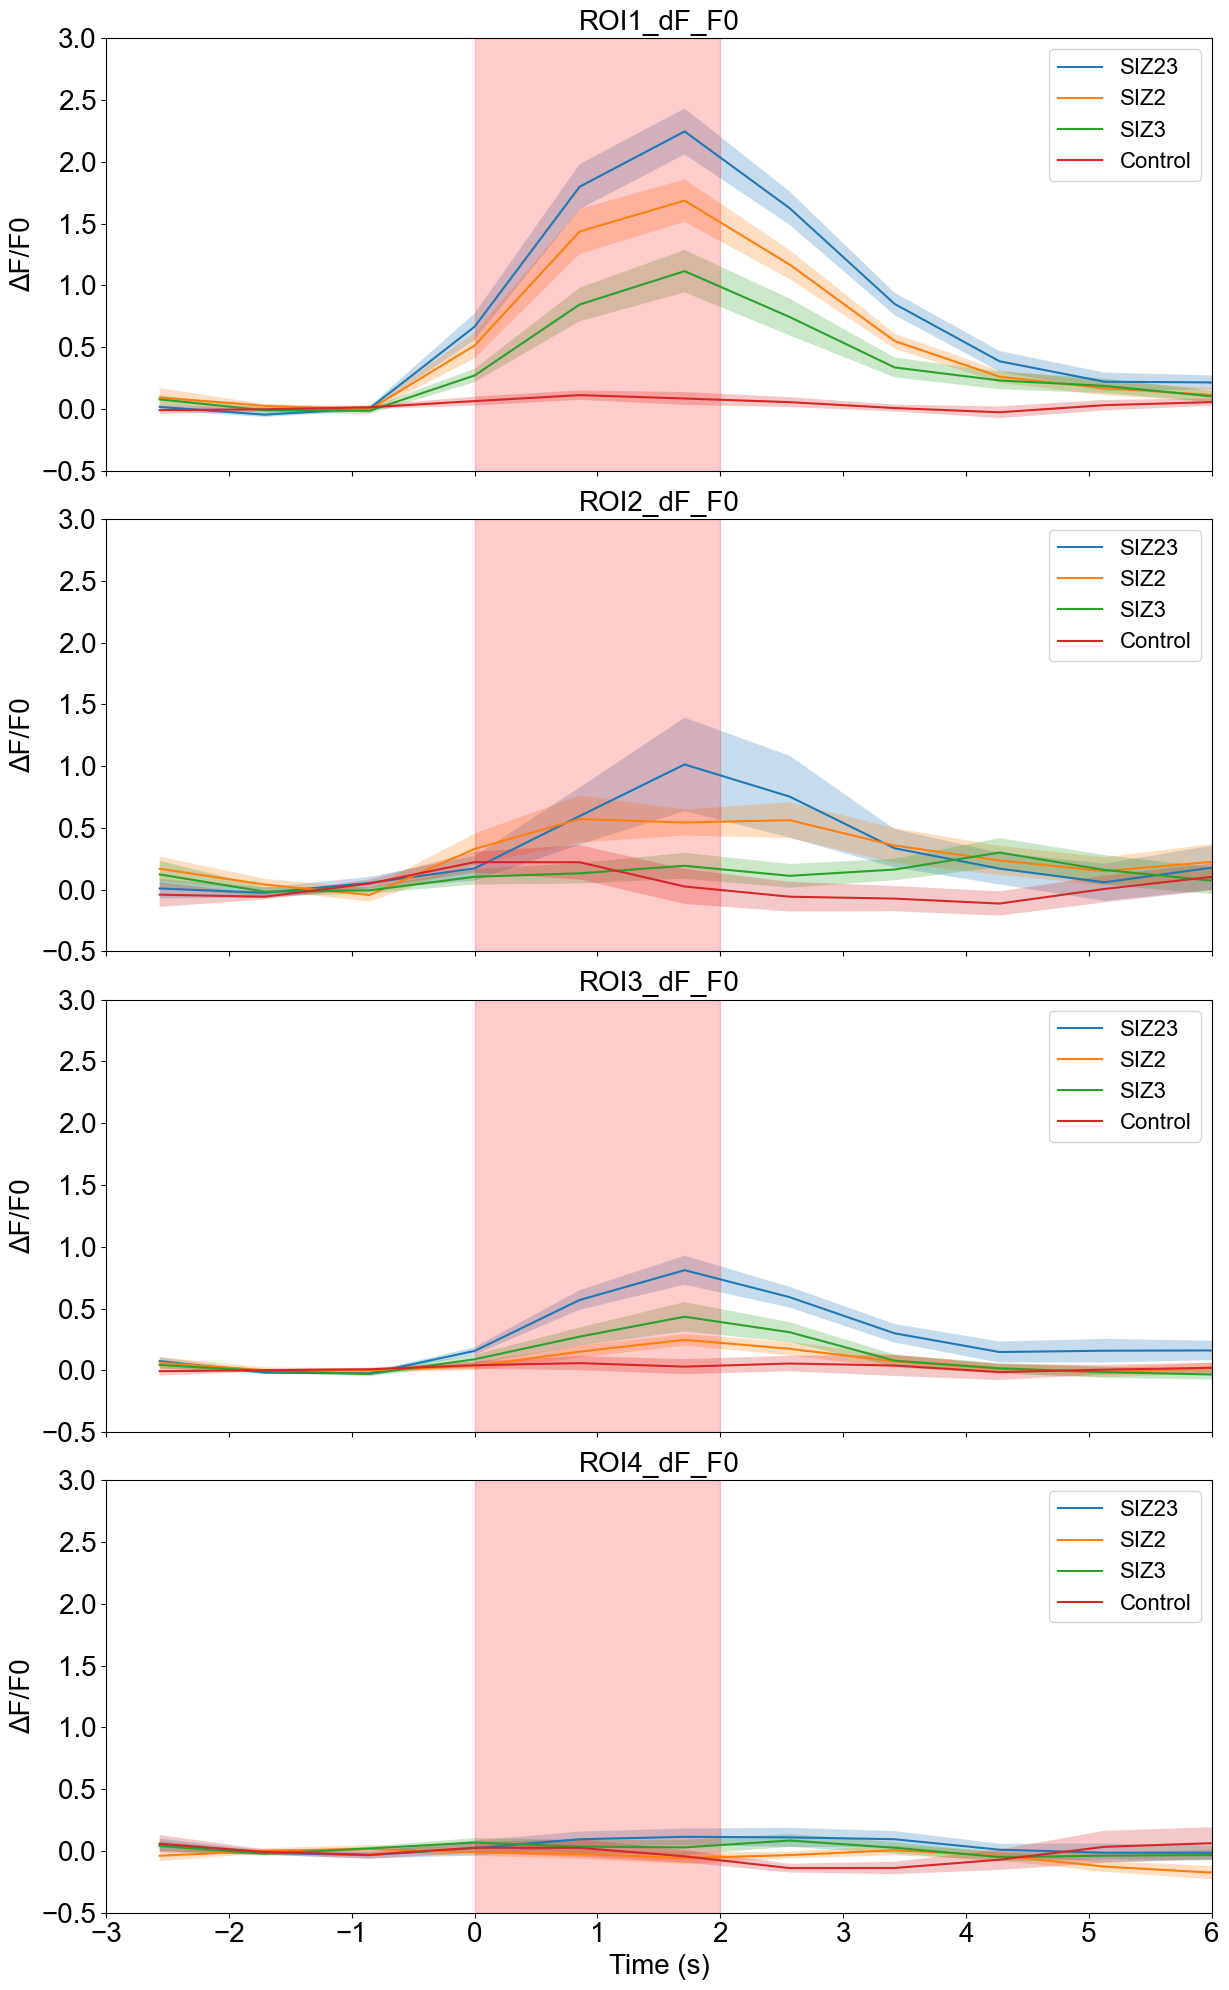

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path


mpl.rcParams.update({
    'font.family': 'Arial',
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'legend.fontsize': 16
})

f_rec = 1.17 # imaging frame rate in Hz

parent_dir = Path(
    r'Z:\Nino\Projects\SIZ_WaddellLab\SIZ'
)

# Find ROI dF/F0 columns
roi_dff_cols = [
    c for c in master_df.columns
    if c.endswith('_dF_F0')
]

# Average responses across repeated trials within each brain
brain_average = (
    master_df
    .groupby(
        [
            'brain',
            'condition',
            'new_frames'
        ]
    )[roi_dff_cols]
    .mean()
    .reset_index()
)

# Average responses across brains
condition_average = (
    brain_average
    .groupby(
        [
            'condition',
            'new_frames'
        ]
    )[roi_dff_cols]
    .agg(['mean','sem'])
    .reset_index()
)

# Convert frames to seconds
condition_average['time_s'] = (
    condition_average['new_frames'] / f_rec
)

conditions = {
    1: "SIZ23",
    2: "SIZ2",
    3: "SIZ3",
    4: "Control"
}

# Plotting
fig, axes = plt.subplots(
    len(roi_dff_cols),
    1,
    figsize=(12, 5*len(roi_dff_cols)),
    sharex=True
)

# If only one ROI
if len(roi_dff_cols) == 1:
    axes = [axes]

for ax, roi in zip(axes, roi_dff_cols):

    for cond, label in conditions.items():

        cond_data = condition_average[
            condition_average['condition'] == cond
        ]

        if len(cond_data) == 0:
            continue

        mean = cond_data[(roi,'mean')]
        sem = cond_data[(roi,'sem')]
        time = cond_data['time_s']

        ax.plot(
            time,
            mean,
            label=label
        )

        ax.fill_between(
            time,
            mean-sem,
            mean+sem,
            alpha=0.25
        )

    # define stimulation period
    ax.axvspan(
        0,
        2,
        color='red',
        alpha=0.2
    )

    ax.set_ylabel(
        "ΔF/F0"
    )

    ax.set_title(
        roi
    )

    ax.set_xlim(
        -3,
        6
    )

    ax.set_ylim(
        -0.5,
        3
    )

    ax.legend(
        loc='upper right'
    )

axes[-1].set_xlabel(
    "Time (s)"
)

plt.tight_layout()
plt.savefig(
    parent_dir / "SIZ_eachROI_dF_F0.png",
    dpi=300
)
plt.savefig(
    parent_dir / "SIZ_eachROI_dF_F0.svg",
    format="svg"
)
plt.show()

Area under the curve during stim period

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path


# Load dataframe
parent_dir = Path(
    r"Z:\Nino\Projects\SIZ_WaddellLab\SIZ"
)
master_df = pd.read_csv(
    parent_dir / "master_data_with_F0_dF_F0.csv"
)

f_rec = 1.17  # frame rate Hz
stim_duration = 2  # optogenetic stimulation in seconds

# Find dF/F0 ROI columns
dff_cols = [
    c for c in master_df.columns
    if "_dF_F0" in c
]

# Calculate area under the curve AUC
results = []

for brain in master_df['brain'].unique():

    df_brain = master_df[
        master_df['brain'] == brain
    ]

    for condition in sorted(
        df_brain['condition'].dropna().unique()
    ):

        df_cond = df_brain[
            df_brain['condition'] == condition
        ]

        for roi in dff_cols:

            # Average all stimulation cycles
            trace = (
                df_cond
                .groupby('new_frames')[roi]
                .mean()
                .reset_index()
                .sort_values('new_frames')
            )

            t = trace['new_frames'].values / f_rec
            y = trace[roi].values

            # remove NaNs
            valid = ~(np.isnan(t) | np.isnan(y))

            t = t[valid]
            y = y[valid]

            if len(y) < 5:
                continue


            # Stimulation window
            stim_mask = (
                (t >= 0) &
                (t <= stim_duration)
            )

            if np.sum(stim_mask) < 2:
                continue

            t_stim = t[stim_mask]
            y_stim = y[stim_mask]

            # AUC during stim period 
            auc = np.trapz(
                y_stim,
                t_stim
            )

            results.append({

                "brain": brain,
                "condition": condition,
                "ROI": roi,
                "AUC_0_2s": auc
            })


# Save results
results_df = pd.DataFrame(results)
print(results_df.head())
out_path = parent_dir / "AUC_by_condition_ROI3.csv"

results_df.to_csv(
    out_path,
    index=False
)

print(
    f"Saved {out_path} ({len(results_df)} rows)"
)

     brain  condition         ROI  AUC_0_2s
0  brain12          1  ROI1_dF_F0  2.362408
1  brain12          1  ROI2_dF_F0 -0.340640
2  brain12          1  ROI3_dF_F0  0.929086
3  brain12          1  ROI4_dF_F0  0.050376
4  brain12          2  ROI1_dF_F0  2.210194
Saved Z:\Nino\Projects\SIZ_WaddellLab\SIZ\AUC_by_condition_ROI3.csv (224 rows)
